# សប្ដាហ៍ទី 2 · វិធាន និងការសម្រេចចិត្ត

ប្រព័ន្ធព័ត៌មានអនុវត្តតាមវិធានដែលមនុស្សជាអ្នកសម្រេច។ ក្នុងសប្តាហ៍នេះ អ្នកនឹងសរសេរវិធានទាំងនោះចំនួនពីរជាភាសា Python, សាកល្បងវានៅចំណុចព្រំដែន (edges), និងជ្រើសរើសតួលេខដោយខ្លួនឯង។

* សំណួរប្រចាំសប្តាហ៍៖ តើប្រព័ន្ធធ្វើការសម្រេចចិត្តយ៉ាងដូចម្តេច ហើយតើនរណាជាអ្នកជ្រើសរើសវិធាននេះ?
* គោលការណ៍ទី២៖ វិធានត្រូវច្បាស់លាស់។ ដាក់ឈ្មោះអោយតួលេខរបស់អ្នក។ អ្នកត្រូវប្រាកដថាលក្ខខណ្ឌក្នុងវិធានរបស់អ្នកគ្របដណ្តប់គ្រប់ករណី និងសាកល្បងនៅចំណុចព្រំដែន។

*Campus FoodBridge ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

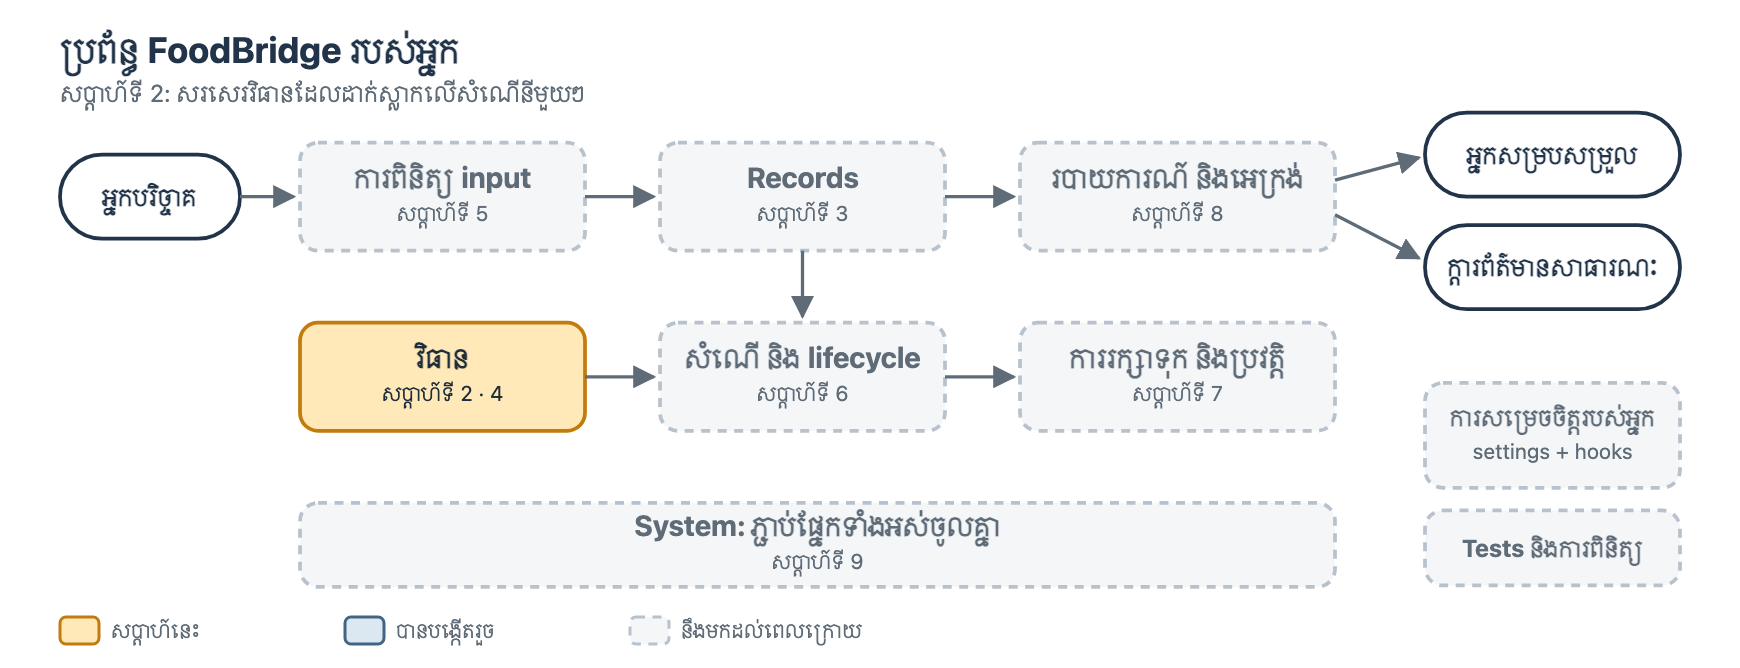

## មុនពេលចាប់ផ្ដើម

1. ចុចលើពាក្យ Copy to Drive (ឬ ចូលទៅកាន់ File​​ រួចចុច Save a copy in Drive)​ រួចធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. Run setup cell។ Run វាម្ដងទៀត ក្រោយពេល runtime restart។
3. ⭐ = កម្រិតមូលដ្ឋាន សម្រាប់គ្រប់គ្នា, ⭐⭐ = សម្រាប់សាកល្បងបន្ថែម។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ FoodBridge
# វាដកយក (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
bridge.set_language("km")     # screens and checks in Khmer
print("✅ ប្រព័ន្ធ FoodBridge រួចរាល់ហើយ (version " + bridge.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")


## ចាប់ផ្ដើមថ្នាក់ · ចែករំលែកកិច្ចការស្រាវជ្រាវទី 1 (10 នាទី)

ជាក្រុមបីនាក់ ចែករំលែកប្រព័ន្ធព័ត៌មានដែលអ្នកបានស្រាវជ្រាវ។

1. តើនរណាជាអ្នកប្រើប្រាស់វា ហើយតើវាផ្ទុកទិន្នន័យអ្វីខ្លះ?
2. តើអ្នកបានរកឃើញច្បាប់ (rule) អ្វីខ្លះ? តើច្បាប់នោះត្រូវបានសរសេរទុកនៅកន្លែងណាមួយ ឬមានតែនៅក្នុងគំនិតរបស់មនុស្ស?
3. តើមានអ្វីអាចនឹងខុសឆ្គង ហើយតើនរណានឹងរងផលប៉ះពាល់?

📝 **គំនិតមួយពីមិត្តរួមថ្នាក់ ដែលខ្ញុំចង់ចងចាំ:**

## វគ្គទី 1 · រៀន: របៀបដែលកម្មវិធីកុំព្យូទ័រ (Programming) ធ្វើការសម្រេចចិត្ត (៣០ នាទី)

### គំនិតសំខាន់: វិធានអាជីវកម្ម (business rule)

វិធានអាជីវកម្មគឺជាការសម្រេចចិត្តដែលស្ថាប័នមួយបង្កើតឡើងអំពីរបៀបដែលការងារត្រូវអនុវត្ត។ ឧទាហរណ៍៖ "ពិន្ទុប្រឡងចាប់ពី ៥០ ឡើងទៅគឺជាប់" ឬ "ក្មេងអាយុក្រោម ៦ ឆ្នាំធ្វើដំណើរដោយឥតគិតថ្លៃ។" នៅក្នុងប្រព័ន្ធបរិច្ចាកអាហាររបស់យើង អ្នកសម្របសម្រួលបាននិយាយថា៖

> "ប្រសិនបើការផ្តល់ជូនមិនទាន់ត្រូវបានអនុម័តទេ វាត្រូវរង់ចាំសិន (hold)។ ប្រសិនបើវាត្រូវបានអនុម័ត និងមានចំនួន ២០ ចំណែក ឬច្រើនជាងនេះ យើងនឹងបញ្ជូនក្រុម(team)មួយទៅប្រមូលយក។ បើមិនដូច្នេះទេ អ្នកស្ម័គ្រចិត្តម្នាក់គឺគ្រប់គ្រាន់ហើយ (standard)។"

មនុស្សជាអ្នកជ្រើសរើសវិធាន។ កម្មវិធីកុំព្យូទ័រអនុវត្តវាដដែលៗដូចគ្នារាល់ដង ចំពោះរាល់ការផ្តល់ជូន នៅគ្រប់ពេលវេលា។ នេះមានប្រយោជន៍ តែវាមានគ្រោះថ្នាក់ផងដែរ៖ វិធានដែលខុសនឹងត្រូវបានអនុវត្តយ៉ាងខុសឆ្គងរាល់ដង។ ដូច្នេះវិធានត្រូវតែសរសេរឲ្យបានច្បាស់លាស់ និងសាកល្បងនៅចំណុចព្រំដែន។

### 1 · ការប្រៀបធៀបផ្ដល់ `True` ឬ `False`

ការប្រៀបធៀបផ្តល់នូវតម្លៃ True ឬ False (ពិត ឬ មិនពិត): ការប្រៀបធៀបអត្ថបទគឺត្រូវតែដូចគ្នាពិតប្រាកដ ដូច្នេះអក្សរធំ-តូចគឺសំខាន់។ ការផ្លាស់ប្តូរតួអក្សរតែមួយអាចផ្លាស់ប្តូរលទ្ធផលថាអ្នកណាទទួលបានក្រុម (team)។

| Python | អត្ថន័យ |
|---|---|
| `==` `!=` | ស្មើ, មិនស្មើ |
| `<` `<=` | តូចជាង, តូចជាង ឬស្មើ |
| `>` `>=` | ធំជាង, ធំជាង ឬស្មើ |

🤔 **ទាយមើល** បន្ទាត់នីមួយៗ មុននឹង run cell។

In [ ]:
portions = 20
print(portions >= 20)
print(portions > 20)
print(portions == 20)
print("bread" == "Bread")

**ការទាយ:** …  **លទ្ធផល:** …  **រឿងដែលធ្វើឱ្យភ្ញាក់ផ្អើល:** …

បន្ទាត់ចុងក្រោយគឺ `False`: ការប្រៀបធៀប text ត្រូវតែដូចគ្នាបេះបិទ ដូច្នេះអក្សរធំ និងអក្សរតូចគឺខុសគ្នា។ "20 ឬច្រើនជាងនេះ" គឺ `>= 20`; "ច្រើនជាង 20" គឺ `> 20`។ តួអក្សរតែមួយ អាចប្ដូរថានរណាបានក្រុម។

### 2 · ការផ្សំលក្ខខណ្ឌ: `and`(និង), `or`(ឬ), `not`(មិន)

In [ ]:
approved = True
portions = 25
print(approved and portions >= 20)   # ទាំងពីរត្រូវតែ True
print(not approved)                  # ផ្ទុយ
print(portions >= 20 or portions < 0)  # យ៉ាងហោចណាស់មួយត្រូវតែ True

### 3 · `if` និង `else`: ការជ្រើសរើសអ្វីដែលត្រូវដំណើរការ

បន្ទាត់ដែលមាន if បញ្ចប់ដោយសញ្ញាចុចពីរ (:)។ 
បន្ទាត់ខាងក្រោមត្រូវតែចូលបន្ទាត់ (indented) ចំនួន ៤ space។ 
ការចូលបន្ទាត់មិនមែនគ្រាន់តែជាការតុបតែងទេ វាជាអ្នកកំណត់ពីអ្វីដែលជាកម្មសិទ្ធិរបស់អ្វី។

In [ ]:
temperature = 31
if temperature >= 30:
    print("Hot: keep the food in the shade")
else:
    print("Normal temperature")
print("This line always runs")

- បន្ទាត់ដែលមាន `if` បញ្ចប់ដោយសញ្ញា colon `:`។
- បន្ទាត់ដែលជារបស់វា ត្រូវ **ចូលបន្ទាត់ (indent)** 4 ដកឃ្លា (spaces)។ នៅក្នុង Python ការចូលបន្ទាត់មិនមែនសម្រាប់លម្អទេ; វាកំណត់ថាបន្ទាត់ណាជារបស់អ្វី។

### 4 · `elif`: ជម្រើសច្រើនជាងពីរនឹងត្រូវបានត្រួតពិនិត្យតាមលំដាប់

Python ត្រួតពិនិត្យលក្ខខណ្ឌពីលើចុះក្រោម ហើយដំណើរការតែជម្រើសដំបូងដែលពិត (True) ប៉ុណ្ណោះ។

In [ ]:
mark = 72
if mark >= 80:
    grade = "A"
elif mark >= 65:
    grade = "B"
elif mark >= 50:
    grade = "C"
else:
    grade = "fail"
print(grade)

🤔 ពិន្ទុ 65 គត់ ទទួលបាននិទ្ទេសអ្វី? ចុះ 64 វិញ? ប្ដូរ `mark` ហើយពិនិត្យមើល។

**ចម្លើយរបស់ខ្ញុំ:** …

### 5 · ដាក់ឈ្មោះឱ្យតម្លៃរបស់អ្នក

តម្លៃនៅក្នុងវិធានមួយគឺជាការសម្រេចចិត្ត។ ត្រូវដាក់ឈ្មោះឱ្យវាដើម្បីឱ្យមនុស្សអាចស្វែងរក យល់ពីវា និងផ្លាស់ប្តូរវានៅកន្លែងតែមួយ។ តាមទម្លាប់ ឈ្មោះជាអក្សរធំគឺជាតម្លៃថេរ (constants)។

```python
TEAM_PICKUP_MIN_PORTIONS = 20      # អ្នកសម្របសម្រួលជាអ្នកសម្រេច

if portions >= TEAM_PICKUP_MIN_PORTIONS:
    ...
```

### 6 · Function ដំបូង: វេចខ្ចប់វិធានមួយ

function ផ្តល់ឈ្មោះឱ្យវិធានមួយ ទទួលយកធាតុចូល និងបញ្ជូនត្រឡប់មកវិញ (returns) នូវចម្លើយមួយ។ 

def បង្ហាញកន្លែងចាប់ផ្តើម function ចំណែក return បញ្ជូនចម្លើយត្រឡប់មកវិញ ហើយបញ្ឈប់ដំណើរការរបស់ function​ ត្រឹមនោះ។ អ្នកអាចហៅវិធានដដែលៗច្រើនដងជាមួយធាតុចូលផ្សេងៗគ្នា។

In [ ]:
def is_hot(temperature):
    if temperature >= 30:
        return True
    return False

print(is_hot(31))
print(is_hot(25))

- `def` ចាប់ផ្ដើម function; `temperature` គឺជា input របស់វា។
- `return` បញ្ជូនចម្លើយត្រឡប់មកវិញ ហើយ **បញ្ឈប់** function។
- អ្នកអាចហៅ (call) វិធានដដែលនេះច្រើនដង ជាមួយ input ផ្សេងៗគ្នា។ នោះហើយជាអ្វីដែលប្រព័ន្ធធ្វើ សម្រាប់សំណើនីមួយៗ។

## វគ្គទី 2 · អនុវត្ត និងវាយតម្លៃ (60 នាទី)

### ⭐ P1 · ប៉ាន់ស្មានលទ្ធផលនៃការប្រៀបធៀប

សរសេរការប៉ាន់ស្មានឬរំពឹងទុករបស់អ្នកសម្រាប់បន្ទាត់នីមួយៗជាមុនសិនមុនពេល run។

**រំពឹងថា:** ពិត​ True/ មិនពិត False  **លទ្ធផលជាក់ស្តែង:** …

* print(hours_left <= 3)​                         រំពឹងថា: ...  លទ្ធផលជាក់ស្តែង: ...
* print(hours_left < 3)​                          រំពឹងថា: ...  លទ្ធផលជាក់ស្តែង: ...
* print(hours_left != 3)​                         រំពឹងថា: ...  លទ្ធផលជាក់ស្តែង: ...
* print(hours_left >= 1 and hours_left <= 12)​​    រំពឹងថា: ...  លទ្ធផលជាក់ស្តែង: ...
* print(not hours_left > 12)​​                     រំពឹងថា: ...  លទ្ធផលជាក់ស្តែង: ...

In [ ]:
hours_left = 3
print(hours_left <= 3)
print(hours_left < 3)
print(hours_left != 3)
print(hours_left >= 1 and hours_left <= 12)
print(not hours_left > 12)

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`True`, `False`, `False`, `True`, `True`។ បន្ទាត់ទីពីរគឺជាអន្ទាក់ព្រំដែន: `3 < 3` គឺ `False`។

</details>

### ⭐ P2 · កែសម្រួលកំហុស (bug) នៅព្រំដែន

វិធានរបស់អ្នកសម្របសម្រួលគឺ *"20 ចំណែក **ឬច្រើនជាងនេះ** ត្រូវការក្រុម (team)។"

កូដនេះមានកំហុស(bug)មួយ។ សាកល្បងវាជាមួយ 19, 20 និង 21 រួចស្វែងរកកំហុសនោះហើយកែតម្រូវវា។

In [ ]:
def needs_team(portions):
    if portions > 20:
        return True
    return False

print(19, needs_team(19))
print(20, needs_team(20))   # តើនេះគួរតែជាអ្វី?
print(21, needs_team(21))

* print(19, needs_team(19))     តើនេះគួរតែជាអ្វី? True/False
* print(20, needs_team(20))     តើនេះគួរតែជាអ្វី? True/False
* print(21, needs_team(21))     តើនេះគួរតែជាអ្វី? True/False

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`> 20` ត្រូវតែជា `>= 20`។ មានតែករណី **ព្រំដែន** (20 គត់) ទេ ដែលបង្ហាញ bug នេះ; 19 និង 21 មើលទៅត្រឹមត្រូវ។ នេះហើយជាមូលហេតុដែលយើងតែងតែ test នៅព្រំដែន មិនមែនត្រឹមតែតម្លៃធម្មតាមួយទេ។

</details>

### ⭐ P3 · កែសម្រួលលំដាប់លក្ខខណ្ឌ (Order of branch)

ប្រសិនបើលក្ខខណ្ឌត្រួតស៊ីគ្នា អ្នកត្រូវដាក់លក្ខខណ្ឌដែលតូចចង្អៀតជាងគេបំផុត (narrowest) នៅខាងលើគេជានិច្ច ព្រោះកូដនឹងឈប់ដំណើរការនៅពេលវាជួបលក្ខខណ្ឌដំបូងដែលពិត។

In [ ]:
def urgency_level(hours_left):
    if hours_left <= 12:
        return "soon"
    elif hours_left <= 3:
        return "urgent"
    else:
        return "later"

print(urgency_level(2), urgency_level(3), urgency_level(4), urgency_level(13))

**ហេតុអ្វីលទ្ធផលមិនចេញជា urgent?** 

ចម្លើយរបស់អ្នក: ...

<details><summary>មើលចម្លើយគំរូមួយ</summary>

2 ម៉ោងក៏ `<= 12` ដែរ ដូច្នេះ branch ទីមួយឈ្នះ ហើយ function return `"soon"` មុនពេលវាបានពិនិត្យ `<= 3`។ ដាក់លក្ខខណ្ឌដែល **ចង្អៀតបំផុត** មុនគេ។ លទ្ធផលដែលរំពឹងទុកក្រោយពេលជួសជុល: `urgent urgent soon later`។

</details>

### ⭐ P4 · សរសេរវិធានតូចមួយ

ផ្ទះបាយរបស់អង្គការដៃគូមួយ អាចទទួលអាហារដែលដឹកមកបាន **យ៉ាងច្រើនបំផុត 50 ចំណែក**។

ចូរសរសេរ `fits_kitchen(portions)` ដែល return `True` ឬ `False`តាមលក្ខខណ្ឌដែលបង្ហាញខាងលើ។

អ្នកអាចប្រើ ចំនួនថេរ (constant) ដែលមានឈ្មោះបង្ហាញចំនួនចំណែកអាហារដែលអង្គការអាចទទួលបាន។ 

ចូរសាកល្បុងតម្លៃជុំវិញព្រំដែន (49, 50 និង 51)

In [ ]:
# សូមបញ្ចូលកូដនៅទីនេះ (លុប​ pass​ ចេញ)

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
def fits_kitchen(portions):
    return portions <= KITCHEN_MAX_PORTIONS
```

ការប្រៀបធៀបមួយ **គឺជា** `True` ឬ `False` រួចទៅហើយ ដូច្នេះអ្នកអាច return វាដោយផ្ទាល់។ លទ្ធផលដែលរំពឹងទុក: `True True False`។

</details>

### ⭐⭐ S1 · លក្ខខណ្ឌពីរ

អ្នកស្ម័គ្រចិត្តចង់បានវិធានពិសេសមួយ: បញ្ជូនក្រុមមួយ ពេលសំណើ **ធំ (20+) ឬបន្ទាន់ខ្លាំង (2 ម៉ោង ឬតិចជាងនេះ)** ប៉ុន្តែលុះត្រាតែវាត្រូវបានអនុម័ត។ 

សរសេរ `send_team(portions, hours_left, approved)` ហើយ តេស្ត (test) ករណីបួនដែលអ្នកជ្រើសរើស រួមទាំងករណីព្រំដែនមួយ។

In [ ]:
def send_team(portions, hours_left, approved):
    # សរសេរវិធានរបស់អ្នកនៅទីនេះ​ (លុប​ pass​ ចេញ)
    pass

ចូរសរសេរចំណាប់អារម្មណ៍ ឬការយល់ឃើញ ឬចម្ងល់របស់អ្នកអំពីប្រធានបទដែលបានរៀនមកនេះនៅខាងក្រោម។

....

### ⚖️ ល្អ ឬមានហានិភ័យ?

ជំនួយការ AI មួយបានសរសេរ **Version A** សម្រាប់វិធានរបស់អ្នកសម្របសម្រួល។ **Version B** គឺជាការសរសេរឡើងវិញ។ ទាំងពីរដំណើរការបានដោយគ្មានបញ្ហា(error)។

**Version A**

```python
def label(p, a):
    if p > 20 and a == True:
        return "team"
    elif a == True:
        return "standard"
```

**Version B**

```python
TEAM_PICKUP_MIN_PORTIONS = 20

def pickup_label(portions, approved):
    if not approved:
        return "hold"
    if portions >= TEAM_PICKUP_MIN_PORTIONS:
        return "team"
    return "standard"
```

ដោយផ្អែកលើ **គោលការណ៍ទី 2 (វិធានច្បាស់លាស់)**​ ចូររកបញ្ហា **យ៉ាងហោចណាស់បី** ក្នុង Version A។

សម្រាប់បញ្ហានីមួយៗ ប្រាប់ថាសំណើណាដែលនឹងត្រូវបានដោះស្រាយខុស។

📝 **បញ្ហាដែលខ្ញុំបានរកឃើញក្នុង Version A:**

1.
2.
3.

<details><summary>មតិរបស់គ្រូ</summary>

1. **ព្រំដែន:** `p > 20` ឱ្យសំណើ 20 ចំណែកគត់ ទៅយកតាមរបៀប standard ដែលផ្ទុយនឹងវិធាន។
2. **ករណីដែលខ្វះ:** ពេល `a` ជា `False` គ្មានអ្វីត្រូវបាន return ទេ ដូច្នេះ function ផ្ដល់ `None` មិនមែន `"hold"` ទេ។ អេក្រង់នឹងបង្ហាញ "None" ឬ program អាច crash នៅពេលក្រោយ។
3. **ការសម្រេចចិត្តដែលលាក់:** លេខ 20 ត្រូវបានកប់នៅក្នុង code។ គ្មាននរណាអាចមើលឃើញ ឬប្ដូរការសម្រេចចិត្តរបស់អ្នកសម្របសម្រួលបានទេ បើមិនអាន logic របស់វា។
4. **ឈ្មោះ:** `p` និង `a` មិនប្រាប់អ្វីសោះ។ (`a == True` ក៏ដំណើរការដែរ ប៉ុន្តែវែងជាង `a`។)

Version B ដោះស្រាយគ្រប់ករណី ដាក់ "មិនទាន់អនុម័ត" មុនគេ ដើម្បីកុំឱ្យវាត្រូវបានរំលងឡើយ ហើយដាក់ឈ្មោះឱ្យការសម្រេចចិត្ត។ Code ដែល AI សរសេរ ជារឿយៗ *មើលទៅ* ដូចជារួចរាល់; ការវាយតម្លៃវា មានន័យថា test នៅព្រំដែន ហើយសួរថា "តើមានអ្វីកើតឡើងក្នុងគ្រប់ករណី?"

</details>

## វគ្គទី 3 · បង្កើតផ្នែកនៃប្រព័ន្ធបរិច្ចាកអាហាររបស់អ្នក: វិធានទៅយកអាហារ (60–80 នាទី)

​រាល់ការផ្តល់ជូន (offer) នៅលើអេក្រង់របស់អ្នកសម្របសម្រួល ត្រូវការស្លាកសញ្ញាចំនួនពីរ ដើម្បីជួយសម្រួលដល់ការសម្រេចចិត្ត៖

1. ស្លាកការដឹកជញ្ជូន (Pickup label): តើនរណាជាអ្នកត្រូវទៅយក? (ក្រុមការងារ (team), អ្នកស្ម័គ្រចិត្តម្នាក់ (standard), ឬត្រូវរង់ចាំសិន (hold))
2. ស្លាកភាពបន្ទាន់ (Urgency label): តើត្រូវទៅយកវាឆាប់កម្រិតណា? (បន្ទាន់ (urgent), ឆាប់ៗ (soon), ឬ ពេលក្រោយ (later))

អ្នកត្រូវសរសេរកូដសម្រាប់វិធានទាំងពីរនេះ។

### ផ្នែកទី 1 · `pickup_label` នរណាជាអ្នកទៅយក? 

អ្នកសម្របសម្រួលបានកំណត់វិធានដូចខាងក្រោម៖

"ប្រសិនបើការផ្តល់ជូនមិនទាន់ត្រូវបានអនុម័ត (approved) ទេ វាត្រូវរង់ចាំសិន (hold)។ ប្រសិនបើវាត្រូវបានអនុម័ត ហើយមានចំនួន ២០ ចំណែក (portions) ឬច្រើនជាងនេះ យើងនឹងបញ្ជូនក្រុមមួយទៅ (team)។ បើមិនដូច្នេះទេ អ្នកស្ម័គ្រចិត្តម្នាក់គឺគ្រប់គ្រាន់ហើយ (standard)។"

ភារកិច្ចរបស់អ្នក៖

បំពេញកូដនៅក្នុង function pickup_label។

ប្រើ if, elif, និង else ព្រមទាំងការប្រៀបធៀប (comparisons) ដើម្បីត្រួតពិនិត្យលក្ខខណ្ឌ។

បញ្ជូនត្រឡប់មកវិញ (return) នូវពាក្យ "hold", "team", ឬ "standard" ដោយផ្អែកលើធាតុចូល (inputs) ដែលមាន។

ត្រូវប្រាកដថាអ្នកបានសាកល្បងកូដរបស់អ្នកជាមួយនឹងករណីព្រំដែន (boundary cases) ដូចជាពេលចំនួនចំណែកស្មើនឹង ២០ គត់។

វិធាន: មិនទាន់អនុម័ត → `"hold"` (រង់ចាំការអនុម័ត)។ បានអនុម័ត ហើយមានយ៉ាងហោចណាស់ `TEAM_PICKUP_MIN_PORTIONS` → `"team"` (ទៅជាក្រុម)។ បើមិនដូច្នោះទេ → `"standard"` (ធម្មតា)។ Return ពាក្យទាំងនេះឱ្យដូចបេះបិទ ជាអក្សរតូច។

In [ ]:
TEAM_PICKUP_MIN_PORTIONS = 20

def pickup_label(portions, approved):
    # TODO 1: បើសំណើមិនទាន់ត្រូវបានអនុម័ត return "hold"
    # TODO 2: បើ portions មានយ៉ាងហោចណាស់ TEAM_PICKUP_MIN_PORTIONS return "team"
    # TODO 3: បើមិនដូច្នោះទេ return "standard"
    return "?"

ឥឡូវ ពិនិត្យវា។ ការពិនិត្យនេះធ្វើតេស្តលើករណីព្រំដែននៃតម្លៃរបស់អ្នកផ្ទាល់។ ដូច្នេះវានៅតែដំណើរការ ពេលអ្នកប្ដូរវិធាននៅពេលក្រោយ។

In [ ]:
bridge.check("pickup_label", pickup_label, {"TEAM_PICKUP_MIN_PORTIONS": TEAM_PICKUP_MIN_PORTIONS})

### ផ្នែកទី 2 · `urgency`​ តើត្រូវទៅយកឆាប់កម្រិតណា? (How soon?)

ឥឡូវនេះ អ្នកត្រូវបង្កើតវិធានដោយខ្លួនឯងសម្រាប់ ស្លាកភាពបន្ទាន់ (Urgency)។ 

អ្នកមានទិន្នន័យពីរ៖

* hours_until_expires: ចំនួនម៉ោងដែលនៅសល់មុនពេលអាហារខូចគុណភាព។

* needs_fridge: តើអាហារនេះត្រូវការដាក់ទូទឹកកកដែរឬទេ (True/False)?

ភារកិច្ចរបស់អ្នក៖

* សម្រេចចិត្តដោយខ្លួនឯងនូវតួលេខ (ឧទាហរណ៍៖ ប៉ុន្មានម៉ោងទើបចាត់ទុកថា "បន្ទាន់"?)។

* បង្កើតតម្លៃថេរ (constant variables) ដោយប្រើអក្សរធំ ដើម្បីផ្ទុកតួលេខដែលអ្នកបានសម្រេចចិត្ត (ឧ. URGENT_HOURS = 2)។

* សរសេរfunction urgency ដែលបញ្ជូនត្រឡប់មកវិញនូវពាក្យ "urgent", "soon", ឬ "later" ដោយផ្អែកលើវិធានដែលអ្នកបានកំណត់។

សាកល្បងកូដរបស់អ្នកជាមួយនឹងតម្លៃផ្សេងៗ ដើម្បីធានាថាវាដំណើរការបានត្រឹមត្រូវ។

In [ ]:
URGENT_HOURS = 3
SOON_HOURS = 12

def urgency(hours_left):
    # TODO: return "urgent", "soon" ឬ "later"
    return "?"

In [ ]:
bridge.check("urgency", urgency, {"URGENT_HOURS": URGENT_HOURS, "SOON_HOURS": SOON_HOURS})

### ផ្នែកទី 3 · ការដាក់បញ្ចូលវិធានទៅក្នុងប្រព័ន្ធ

**Hook** គឺជាកន្លែងដែលប្រព័ន្ធអនុញ្ញាតឱ្យអ្នកដាក់ function របស់អ្នកផ្ទាល់ចូល។ នៅទីនេះ អ្នកផ្ដល់វិធានទាំងពីររបស់អ្នកឱ្យប្រព័ន្ធ។ 

មើលជួរឈរ ភាពបន្ទាន់ (`urgency`) និង របៀបទៅយក (`pickup`): ឥឡូវនេះ វាមកពី code **របស់អ្នក**។

នៅចុងថ្ងៃគំរូ សំណើគ្រប់មួយមានការសម្រេចចិត្តរួចហើយ។ ដូច្នេះ cell នេះក៏បន្ថែមសំណើ **ថ្មី** មួយ (25 ចំណែក នៅសល់ 2 ម៉ោង) ដែលមិនទាន់មាននរណាអនុម័ត។ រកវានៅក្នុងរបាយការណ៍: តើវាទទួលបានស្លាកអ្វីខ្លះ ហើយហេតុអ្វី?

In [ ]:
MY_SETTINGS = {
    "TEAM_PICKUP_MIN_PORTIONS": TEAM_PICKUP_MIN_PORTIONS,
    "URGENT_HOURS": URGENT_HOURS,
    "SOON_HOURS": SOON_HOURS,
}
my_system = bridge.System(MY_SETTINGS, hooks={"pickup_label": pickup_label, "urgency": urgency})
my_system.run_day(show=False)
my_system.add_offer({"donor": "Golden Oven Bakery", "contact": "golden@example.org",
                     "food": "Baguettes", "category": "bread", "portions": "25", "hours_left": "2"})
print(my_system.report())

ការដាក់បញ្ចូលវិធានទៅក្នុងប្រព័ន្ធ៖ ប្រព័ន្ធអនុញ្ញាតឲ្យអ្នកដោតបញ្ចូល (plug in) អនុគមន៍ដែលអ្នកបានសរសេរទៅកាន់ប្រព័ន្ធផ្ទាល់។ ប្រសិនបើអនុគមន៍របស់អ្នកគាំង ឬបញ្ជូនចម្លើយដែលមិនត្រឹមត្រូវ ប្រព័ន្ធនឹងបោះពុម្ពការព្រមាន ⚠️ ហើយប្រើវិធានដើម (default) របស់វា ដើម្បីឱ្យការងារអាចដំណើរការបន្តបាន។ ប្រព័ន្ធដែលមនុស្សពឹងផ្អែក ត្រូវតែមានសមត្ថភាពបរាជ័យដោយសុវត្ថិភាព (fail safely) និងប្រាប់ពីមូលហេតុច្បាស់លាស់។


🤔 សង្កេតមើលថា `MY_SETTINGS` ត្រូវបានបង្កើត **ពី** constant របស់អ្នក ជំនួសឱ្យការសរសេរលេខឡើងវិញ។ ហេតុអ្វីបានជាវិធីនេះមានសុវត្ថិភាពជាងការវាយ `20` ម្ដងទៀត?

**ចម្លើយរបស់ខ្ញុំ:** …

### 🧭 ការសម្រេចចិត្តរបស់អ្នក · ពេលណាយើងបញ្ជូនក្រុម ហើយអ្វីទៅដែលបន្ទាន់?

អ្នកសម្របសម្រួលស្នើឱ្យអ្នកផ្ដល់យោបល់អំពីតម្លៃទាំងនេះ។

គិតអំពីមនុស្ស: ក្រុមមានន័យថាមានអ្នកស្ម័គ្រចិត្តច្រើននាក់នៅលើផ្លូវការទៅយកធម្មតា (standard) គឺមនុស្សម្នាក់ដឹកអ្វីៗទាំងអស់។ សំណើបន្ទាន់ត្រូវបានទៅយកមុនគេ។

1. ប្ដូរ `TEAM_PICKUP_MIN_PORTIONS`, `URGENT_HOURS` និង `SOON_HOURS` នៅក្នុង cell ខាងលើ (ផ្នែកទី 1 និងផ្នែកទី 2)។ អ្នកអាចរក្សា default ដដែលបាន បើអ្នកអាចពន្យល់ពីមូលហេតុ។
2. Run ផ្នែកទី 1–3 ម្ដងទៀត។ តេស្តនៅតែអាចឆ្លងរួច ព្រោះវាប្រើលេខរបស់អ្នក។
3. Run cell ខាងក្រោម ដើម្បីមើលថាជម្រើសរបស់អ្នកប្ដូរការងារយ៉ាងដូចម្ដេច។ សំណើនីមួយៗទទួលបានស្លាក សូម្បីតែសំណើដែលត្រូវបានបដិសេធ ឬប្រគល់រួចហើយ ប៉ុន្តែគ្មាននរណាធ្វើតាមស្លាកទាំងនោះទេ: មើល status នៅចុងបន្ទាត់នីមួយៗ។

In [ ]:
for offer in my_system.offers:
    print(offer.id, offer.portions, "portions,", offer.hours_left, "hours left →",
          my_system.label(offer), "/", my_system.urgency(offer), "· status:", offer.status)

📝 **កំណត់ត្រាការសម្រេចចិត្ត · សប្ដាហ៍ទី 2**

| | |
|---|---|
| **ជម្រើសរបស់ខ្ញុំ** | team ចាប់ពី … ចំណែក; urgent ≤ … ម៉ោង; soon ≤ … ម៉ោង |
| **ជម្រើសផ្សេងដែលខ្ញុំបានពិចារណា** | |
| **មូលហេតុដែលខ្ញុំជ្រើសវា** | |
| **នរណាខ្លះរងផលប៉ះពាល់ · ការដោះដូរ (trade-off)** | |

### ⭐⭐ បន្ថែម · ពន្យល់ការសម្រេចចិត្ត

មនុស្សទុកចិត្តវិធានមួយកាន់តែខ្លាំង ពេលពួកគេអាចមើលឃើញថាហេតុអ្វីវាត្រូវបានអនុវត្ត។ សរសេរ `explain_label(portions, approved)` ដែល return ប្រយោគមួយ ដូចជា `"team: 30 portions is at least 20"` ឬ `"hold: waiting for approval"`។ ប្រើ constant របស់អ្នកនៅក្នុងប្រយោគ។

In [ ]:
def explain_label(portions, approved):
    return "?"

print(explain_label(30, True))
print(explain_label(12, True))
print(explain_label(30, False))

## បញ្ចប់

- [ ] ខ្ញុំបានចែករំលែករបកគំហើញពីកិច្ចការស្រាវជ្រាវទី 1 នៅពេលចាប់ផ្ដើមថ្នាក់។
- [ ] ខ្ញុំបានជួសជុល bug នៅព្រំដែន (P2) និង bug លំដាប់ branch (P3)។
- [ ] ខ្ញុំបានរកឃើញបញ្ហាយ៉ាងហោចណាស់បី ក្នុង Version A។
- [ ] `pickup_label` និង `urgency` ជាប់គ្រប់ការពិនិត្យ ហើយរបាយការណ៍ប្រើ function ទាំងពីរនេះ។
- [ ] កំណត់ត្រាការសម្រេចចិត្តរបស់ខ្ញុំ ពន្យល់លេខទាំងបីរបស់ខ្ញុំ។

### កិច្ចការស្រាវជ្រាវទី 2 · វិធាន និង edge case (5%)
(កិច្ចការនេះសម្រាប់ធ្វើនៅផ្ទះ ឬជាការស្រាវជ្រាវបន្ថែម)

ជ្រើសរើសវិធាន (rule) មួយពីប្រព័ន្ធនៅក្នុងជីវភាពប្រចាំថ្ងៃ។

ឧទាហរណ៍៖ 
* ថ្លៃសំបុត្រឡានក្រុងសម្រាប់កុមារ
* ថ្លៃពិន័យសៀវភៅបណ្ណាល័យពេលហួសកំណត់
* កញ្ចប់សេវាកម្មអ៊ីនធឺណិត
* ពិន្ទុប្រឡងជាប់/ធ្លាក់
* ឬលក្ខខណ្ឌនៃការបញ្ចុះតម្លៃនៅហាងទំនិញ...។

សូមឆ្លើយសំណួរខាងក្រោម៖

1. សរសេរវិធាននោះឲ្យបានច្បាស់លាស់បំផុត (ដូចដែលកម្មវិធីកុំព្យូទ័រត្រូវការសម្រាប់យកទៅដំណើរការ)។
2. ផ្តល់ឧទាហរណ៍ចំនួន ៣ ករណី៖
    * ករណីធម្មតាមួយ (Normal case): តម្លៃទូទៅធម្មតា។
    * ករណីព្រំដែនមួយ (Edge case): តម្លៃដែលនៅចំគែមនៃលក្ខខណ្ឌ (ឧ. បើកុមារអាយុក្រោម ៦ ឆ្នាំ តើក្មេងអាយុ ៦ ឆ្នាំគត់ ត្រូវគិតលុយឬអត់?)។
    * ករណីចម្លែកមួយ (Weird case): ធាតុចូលអវិជ្ជមាន ឬមិនធម្មតា (ឧ. បញ្ចូលអាយុជាលេខអវិជ្ជមាន -២)។
    តើប្រព័ន្ធគួរឆ្លើយតបយ៉ាងដូចម្តេចក្នុងករណីនីមួយៗ?
3. តើនរណាជាអ្នកសម្រេចលើវិធាននេះ? ហើយតើនរណានឹងរងផលប៉ះពាល់ ប្រសិនបើអ្នកសរសេរកម្មវិធី (programmer) សរសេរកូដនៅចំណុចព្រំដែនមានកំហុស?


បើអ្នកប្រើជំនួយការ AI ដើម្បីសម្រួលកិច្ចការស្រាវជ្រាវនេះ សូមបង្ហាញកន្លែងឬស្ថានភាពដែលអ្នកបានពិនិត្យ ឬកែតម្រូវវា។
សូមបញ្ជូនកិច្ចការរបស់អ្នកតាមរយៈ email ទៅកាន់ submit.progmis@gmail.com; ថ្ងៃផុតកំណត់ និងឈ្មោះ file នឹងប្រកាសនៅក្នុងថ្នាក់។